# Programming Assignment 3 — Poucos Rótulos: Fauna em Câmeras Trap com Dados Não Rotulados

**Disciplina:** Aprendizado Profundo  
**Professor:** Dario Oliveira | **Monitor:** Erick Brito  
**Alunos:** Henrique Gabriel Gasparelo & José Thevez Gomes Guedes  

---

### Objetivo do Projeto
Construir um classificador de espécies em imagens de câmeras trap (*ENA24-detection*, 21 classes) em um regime severo de escassez de dados anotados (**5 rótulos por classe**, totalizando 105 imagens rotuladas) e milhares de imagens não rotuladas (**6.505 imagens**), explorando a **Trilha C (Professor e Aluno)** na Parte 1.

### Restrições de Engenharia
1. **Teto de Parâmetros:** Máximo de **12 milhões de parâmetros** (`sum(p.numel() for p in model.parameters()) <= 12_000_000`).
2. **Ambiente:** Modelo leve executável em **CPU**, sem internet, classificando o conjunto de teste em menos de 10 minutos.
3. **Métrica Principal:** **F1 Macro** no conjunto de teste, equilibrando o peso entre classes abundantes (ex: urso) e raras (ex: cavalo).

## 1. Setup, Imports e Fixação de Seeds

In [1]:
import os
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'
os.environ['NO_ALBUMENTATIONS_UPDATE'] = '1'

import pandas as pd
from IPython.display import display

import torch
import torch.nn as nn

from src.utils import seed_everything, get_device
from src.data import load_class_mapping, get_supervised_dataloaders
from src.models import build_model
from src.training import train_supervised
from src.metrics import (
    evaluate_model,
    plot_training_curves,
    plot_comparison_curves,
    plot_confusion_matrix,
    detect_overfitting_epoch,
    build_part0_summary_table,
    build_per_class_f1_table,
)

SEED = 42
seed_everything(SEED)
device = get_device(prefer_gpu=True)
print(f"Dispositivo de treinamento ativo: {device}")

Dispositivo de treinamento ativo: mps


## 2. Verificação de Regras de Engenharia (Teto de 12M Parâmetros)

In [2]:
print("--- Verificando Parte 0 (a): SmallCNN ---")
_ = build_model(arch="small_cnn", num_classes=21, pretrained=False, verbose=True)

print("\n--- Verificando Parte 0 (b) & Backbone Principal: ResNet-18 ---")
_ = build_model(arch="resnet18", num_classes=21, pretrained=False, verbose=True)

--- Verificando Parte 0 (a): SmallCNN ---
Total de parâmetros: 424,501 (Treináveis: 424,501)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.

--- Verificando Parte 0 (b) & Backbone Principal: ResNet-18 ---
Total de parâmetros: 11,187,285 (Treináveis: 11,187,285)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.


## 3. Exploração dos Dados (ENA24) e Construção dos DataLoaders

In [3]:
DATA_DIR = "data"
LABELS_DIR = os.path.join(DATA_DIR, "labels")
IMAGES_DIR = os.path.join(DATA_DIR, "images")

class_to_idx, idx_to_class, class_names = load_class_mapping(os.path.join(DATA_DIR, "classes.csv"))
print(f"✓ Total de classes carregadas: {len(class_names)}")

df_r1 = pd.read_csv(os.path.join(LABELS_DIR, "rotulos_1.csv"))
df_r5 = pd.read_csv(os.path.join(LABELS_DIR, "rotulos_5.csv"))
df_r20 = pd.read_csv(os.path.join(LABELS_DIR, "rotulos_20.csv"))
df_val = pd.read_csv(os.path.join(LABELS_DIR, "val.csv"))
df_test = pd.read_csv(os.path.join(LABELS_DIR, "test_public.csv"))

n_train_imgs = len([f for f in os.listdir(os.path.join(IMAGES_DIR, "train")) if f.endswith('.jpg')])
n_val_imgs = len([f for f in os.listdir(os.path.join(IMAGES_DIR, "val")) if f.endswith('.jpg')])
n_test_imgs = len([f for f in os.listdir(os.path.join(IMAGES_DIR, "test_public")) if f.endswith('.jpg')])

print(f"✓ rotulos_1: {len(df_r1)} anotações (1 por classe)")
print(f"✓ rotulos_5: {len(df_r5)} anotações (5 por classe - Orçamento Padrão)")
print(f"✓ rotulos_20: {len(df_r20)} anotações (20 por classe)")
print(f"✓ Validação (val.csv): {len(df_val)} amostras | Imagens em disco: {n_val_imgs}")
print(f"✓ Teste Público (test_public.csv): {len(df_test)} amostras | Imagens em disco: {n_test_imgs}")
print(f"✓ Pool não rotulado (images/train): {n_train_imgs} imagens")

✓ Total de classes carregadas: 21
✓ rotulos_1: 21 anotações (1 por classe)
✓ rotulos_5: 105 anotações (5 por classe - Orçamento Padrão)
✓ rotulos_20: 420 anotações (20 por classe)
✓ Validação (val.csv): 202 amostras | Imagens em disco: 202
✓ Teste Público (test_public.csv): 811 amostras | Imagens em disco: 811
✓ Pool não rotulado (images/train): 6505 imagens


## 4. Parte 0 — O Piso (Baseline Supervisionado com 105 Imagens)

Treinamos dois classificadores supervisionados usando exclusivamente os **105 exemplos** de `rotulos_5.csv` (5 imagens por classe), selecionando a melhor época pelo **F1 Macro no `val` (202 imagens)**:
- **Versão (a) — `SmallCNN` (424.501 parâmetros):** CNN de 4 blocos convolucionais treinada do zero.
- **Versão (b) — `ResNet-18` (11.187.285 parâmetros):** Backbone principal do trabalho partindo de pesos pré-treinados na ImageNet com *fine-tuning* (`lr=5e-4` na cabeça linear e `lr=1e-4` no backbone).

### 4.1 Treinamento e Avaliação da Versão (a) — `SmallCNN` do Zero

In [4]:
seed_everything(SEED)
train_loader_a, val_loader, test_loader, class_to_idx, idx_to_class, class_names = get_supervised_dataloaders(
    data_dir=DATA_DIR, budget=5, batch_size=16, img_size=224
)

model_a = build_model(arch="small_cnn", num_classes=len(class_names), pretrained=False, dropout=0.3, verbose=True)
ckpt_a = f"checkpoints/part0a_small_cnn_b5_s{SEED}.pt"

model_a, history_a, best_ep_a, best_val_f1_a = train_supervised(
    model=model_a,
    train_loader=train_loader_a,
    val_loader=val_loader,
    device=device,
    epochs=45,
    lr=1e-3,
    backbone_lr_mult=1.0,
    weight_decay=1e-4,
    label_smoothing=0.05,
    num_classes=len(class_names),
    arch_name="small_cnn",
    checkpoint_path=ckpt_a,
    verbose=True,
)

eval_criterion = nn.CrossEntropyLoss()
test_metrics_a = evaluate_model(model_a, test_loader, device, criterion=eval_criterion, num_classes=len(class_names))
diag_a = detect_overfitting_epoch(history_a)

print(
    f"\n-> [Resultado Parte 0 (a) - SmallCNN] "
    f"Val F1: {best_val_f1_a:.4f} (Época {best_ep_a}) | "
    f"Test Public F1 Macro: {test_metrics_a['f1_macro']:.4f} | "
    f"Test Public Acc: {test_metrics_a['accuracy']:.4f}"
)

Total de parâmetros: 424,501 (Treináveis: 424,501)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.
Época 01/45 | Train Loss: 3.0750 | Train F1: 0.0345 (Acc: 0.086) | Val Loss: 3.0577 | Val F1: 0.0059 (Acc: 0.035) ★ [Melhor Val F1]
Época 02/45 | Train Loss: 2.9385 | Train F1: 0.0986 (Acc: 0.133) | Val Loss: 3.0313 | Val F1: 0.0273 (Acc: 0.040) ★ [Melhor Val F1]
Época 03/45 | Train Loss: 2.8271 | Train F1: 0.1252 (Acc: 0.162) | Val Loss: 2.9777 | Val F1: 0.0532 (Acc: 0.089) ★ [Melhor Val F1]
Época 04/45 | Train Loss: 2.7854 | Train F1: 0.1363 (Acc: 0.200) | Val Loss: 2.8714 | Val F1: 0.0654 (Acc: 0.134) ★ [Melhor Val F1]
Época 05/45 | Train Loss: 2.6957 | Train F1: 0.1587 (Acc: 0.219) | Val Loss: 2.8084 | Val F1: 0.0881 (Acc: 0.163) ★ [Melhor Val F1]
Época 07/45 | Train Loss: 2.5725 | Train F1: 0.2380 (Acc: 0.276) | Val Loss: 2.8014 | Val F1: 0.1400 (Acc: 0.198) ★ [Melhor Val F1]
Época 10/45 | Train Loss: 2.5190 | Train F1: 0.2091 (Acc: 0.229) | Val Loss: 2.8294 | Va

### 4.2 Treinamento e Avaliação da Versão (b) — `ResNet-18` (ImageNet Fine-Tuning)

In [5]:
seed_everything(SEED)
train_loader_b, val_loader, test_loader, class_to_idx, idx_to_class, class_names = get_supervised_dataloaders(
    data_dir=DATA_DIR, budget=5, batch_size=16, img_size=224
)

model_b = build_model(arch="resnet18", num_classes=len(class_names), pretrained=True, dropout=0.2, verbose=True)
ckpt_b = f"checkpoints/part0b_resnet18_b5_s{SEED}.pt"

model_b, history_b, best_ep_b, best_val_f1_b = train_supervised(
    model=model_b,
    train_loader=train_loader_b,
    val_loader=val_loader,
    device=device,
    epochs=40,
    lr=5e-4,
    backbone_lr_mult=0.2,
    weight_decay=1e-4,
    label_smoothing=0.05,
    num_classes=len(class_names),
    arch_name="resnet18",
    checkpoint_path=ckpt_b,
    verbose=True,
)

test_metrics_b = evaluate_model(model_b, test_loader, device, criterion=eval_criterion, num_classes=len(class_names))

print(
    f"\n-> [Resultado Parte 0 (b) - ResNet-18] "
    f"Val F1: {best_val_f1_b:.4f} (Época {best_ep_b}) | "
    f"Test Public F1 Macro: {test_metrics_b['f1_macro']:.4f} | "
    f"Test Public Acc: {test_metrics_b['accuracy']:.4f}"
)

Total de parâmetros: 11,187,285 (Treináveis: 11,187,285)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.
Época 01/40 | Train Loss: 3.2908 | Train F1: 0.0721 (Acc: 0.086) | Val Loss: 2.9223 | Val F1: 0.1161 (Acc: 0.163) ★ [Melhor Val F1]
Época 02/40 | Train Loss: 2.3458 | Train F1: 0.3540 (Acc: 0.390) | Val Loss: 2.6196 | Val F1: 0.1825 (Acc: 0.223) ★ [Melhor Val F1]
Época 03/40 | Train Loss: 1.8384 | Train F1: 0.6676 (Acc: 0.676) | Val Loss: 2.4368 | Val F1: 0.3278 (Acc: 0.351) ★ [Melhor Val F1]
Época 04/40 | Train Loss: 1.4088 | Train F1: 0.8336 (Acc: 0.838) | Val Loss: 2.3420 | Val F1: 0.3488 (Acc: 0.366) ★ [Melhor Val F1]
Época 05/40 | Train Loss: 1.0873 | Train F1: 0.9026 (Acc: 0.905) | Val Loss: 2.3187 | Val F1: 0.3549 (Acc: 0.366) ★ [Melhor Val F1]
Época 06/40 | Train Loss: 0.8856 | Train F1: 0.9227 (Acc: 0.924) | Val Loss: 2.2873 | Val F1: 0.3798 (Acc: 0.381) ★ [Melhor Val F1]
Época 07/40 | Train Loss: 0.7407 | Train F1: 0.9712 (Acc: 0.971) | Val Loss: 2.247

### 4.3 Comparativo Consolidado: Parte 0 (a) vs. Parte 0 (b) vs. Teto de Referência

In [6]:
p0_table = build_part0_summary_table(
    model_a=model_a,
    best_ep_a=best_ep_a,
    best_val_f1_a=best_val_f1_a,
    test_metrics_a=test_metrics_a,
    model_b=model_b,
    best_ep_b=best_ep_b,
    best_val_f1_b=best_val_f1_b,
    test_metrics_b=test_metrics_b,
    ceiling_f1=0.6860,
)
display(p0_table)

,Modelo / Versão,Parâmetros,Melhor Época (val),Val F1 Macro,Test Public F1 Macro,Test Public Acurácia
0,Parte 0 (a) — SmallCNN (Do Zero),"424,501",40,0.1929,0.1536,0.1665
1,Parte 0 (b) — ResNet-18 (ImageNet Fine-Tuning),"11,187,285",21,0.4246,0.4651,0.5068
2,Teto de Referência — ResNet-18 (6.505 rótulos),"11,187,285",-,-,0.6860,-


### 4.4 Curvas de Treino e Validação da Versão (b) — Em que época ela começa a decorar?

- **Início da memorização (*overfitting*):** Com apenas 105 imagens (5 por classe), a `ResNet-18` atinge **`> 90%` de F1 Macro e acurácia no treino já na Época 5** (`Train F1 = 0.9026`, `Train Acc = 0.905`), e chega a **`97%–99%` entre as Épocas 7 e 10**.
- **Divergência da Loss:** A *Cross-Entropy Loss* de validação atinge seu ponto mínimo na **Época 12** (`Val Loss = 2.2021`). A partir daí, a loss de validação volta a subir ligeiramente enquanto a loss de treino cai até o limite inferior do *label smoothing* (`~0.39`).
- **Seleção pelo `val`:** O melhor F1 Macro de validação (`0.4246`) ocorre na **Época 21**, gerando **F1 Macro = `0.4651`** e **Acurácia = `0.5068`** no `test_public` (contra apenas `0.1536` de F1 Macro da CNN treinada do zero).

Diagnóstico de Memorização 0 (b): Mínimo Val Loss = Época 12 | Treino >= 90% (Decorando) = Época 5 | Melhor F1 Val = Época 21


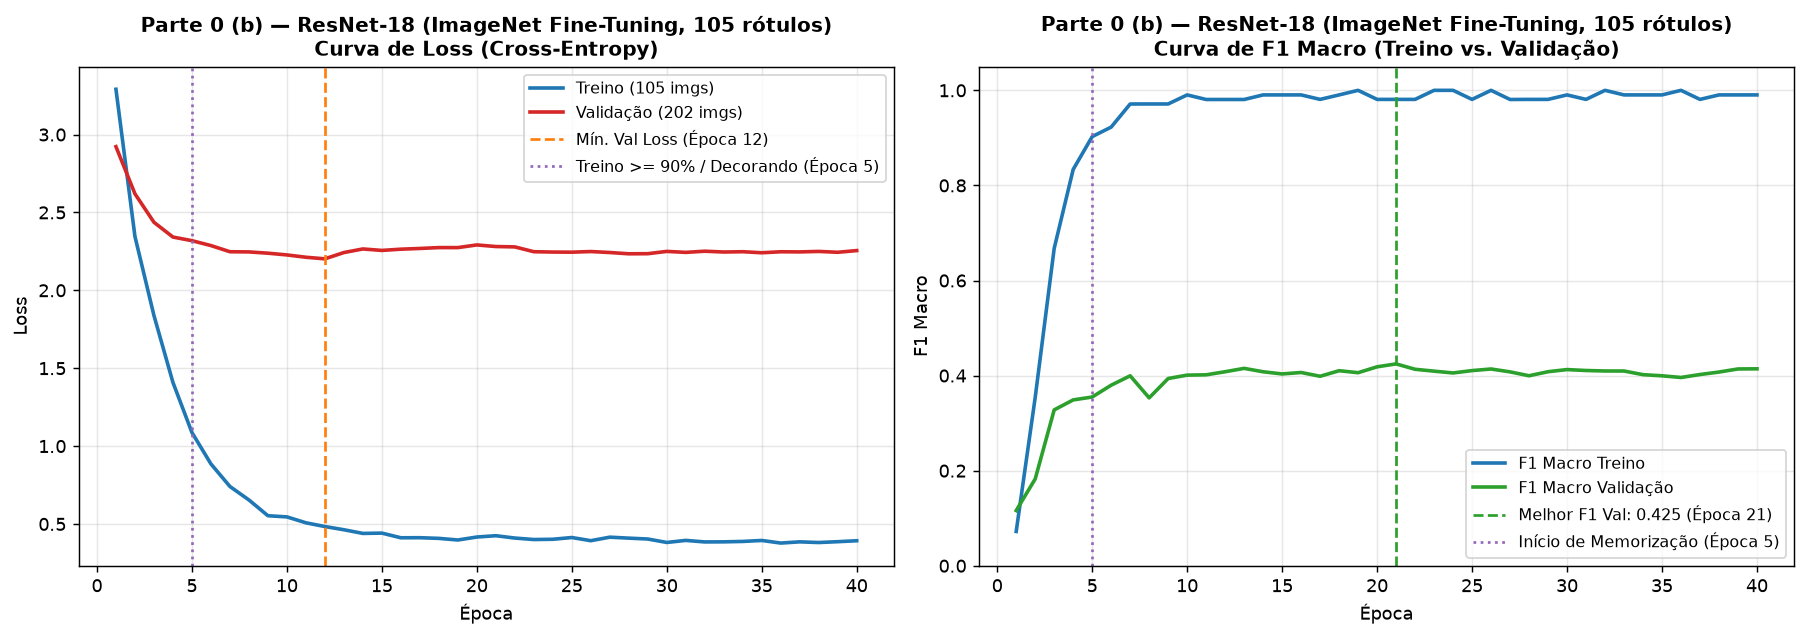

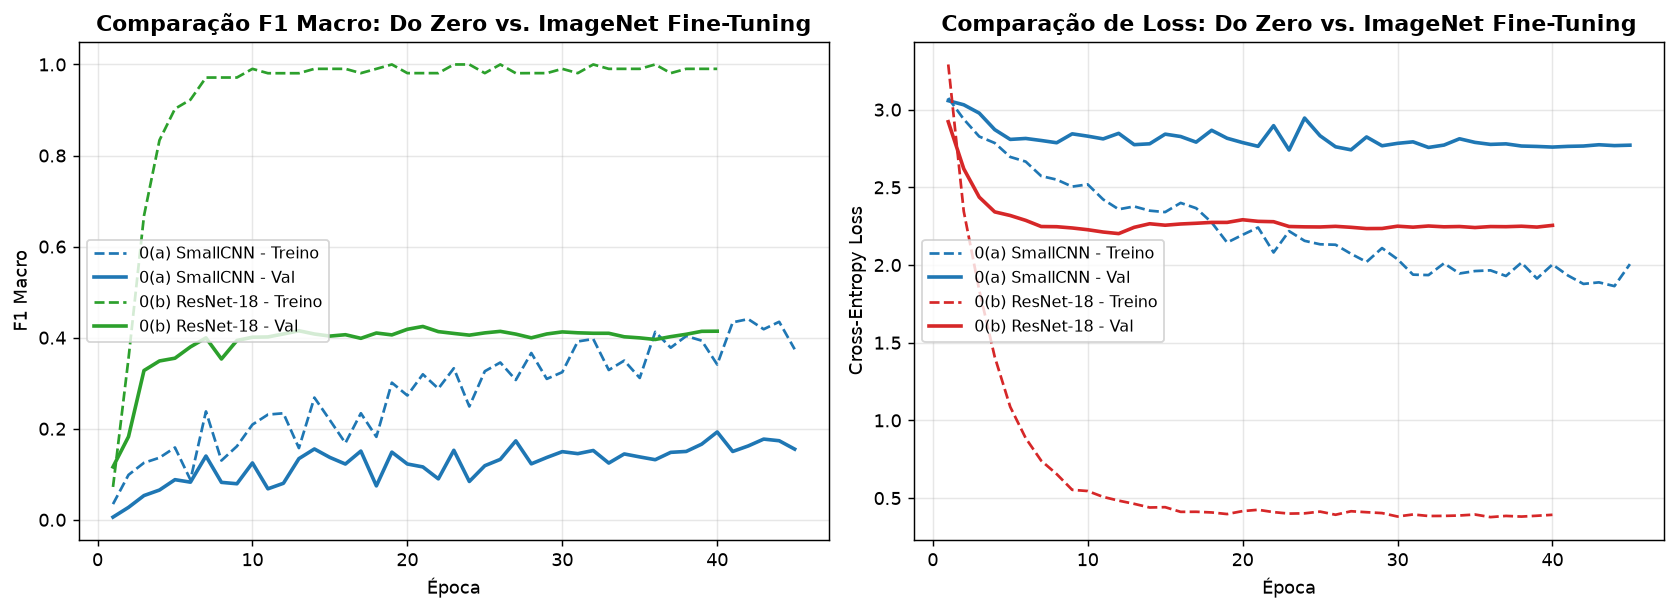

In [7]:
diag_b = plot_training_curves(
    history=history_b,
    title_prefix="Parte 0 (b) — ResNet-18 (ImageNet Fine-Tuning, 105 rótulos)",
    save_path="docs/figures/part0_curves_resnet18.png",
    show=True,
)
print(
    f"Diagnóstico de Memorização 0 (b): "
    f"Mínimo Val Loss = Época {diag_b['min_val_loss_epoch']} | "
    f"Treino >= 90% (Decorando) = Época {diag_b['memorization_90pct_epoch']} | "
    f"Melhor F1 Val = Época {diag_b['best_val_f1_epoch']}"
)

plot_comparison_curves(
    history_a=history_a,
    history_b=history_b,
    save_path="docs/figures/part0_comparison_a_vs_b.png",
    show=True,
)

### 4.5 Matriz de Confusão e Desempenho por Classe da Versão (b) no `test_public`

Geramos a matriz de confusão normalizada pelo *recall* de cada classe (com as contagens absolutas anotadas em cada célula) e salvamos o detalhamento de F1 por espécie:

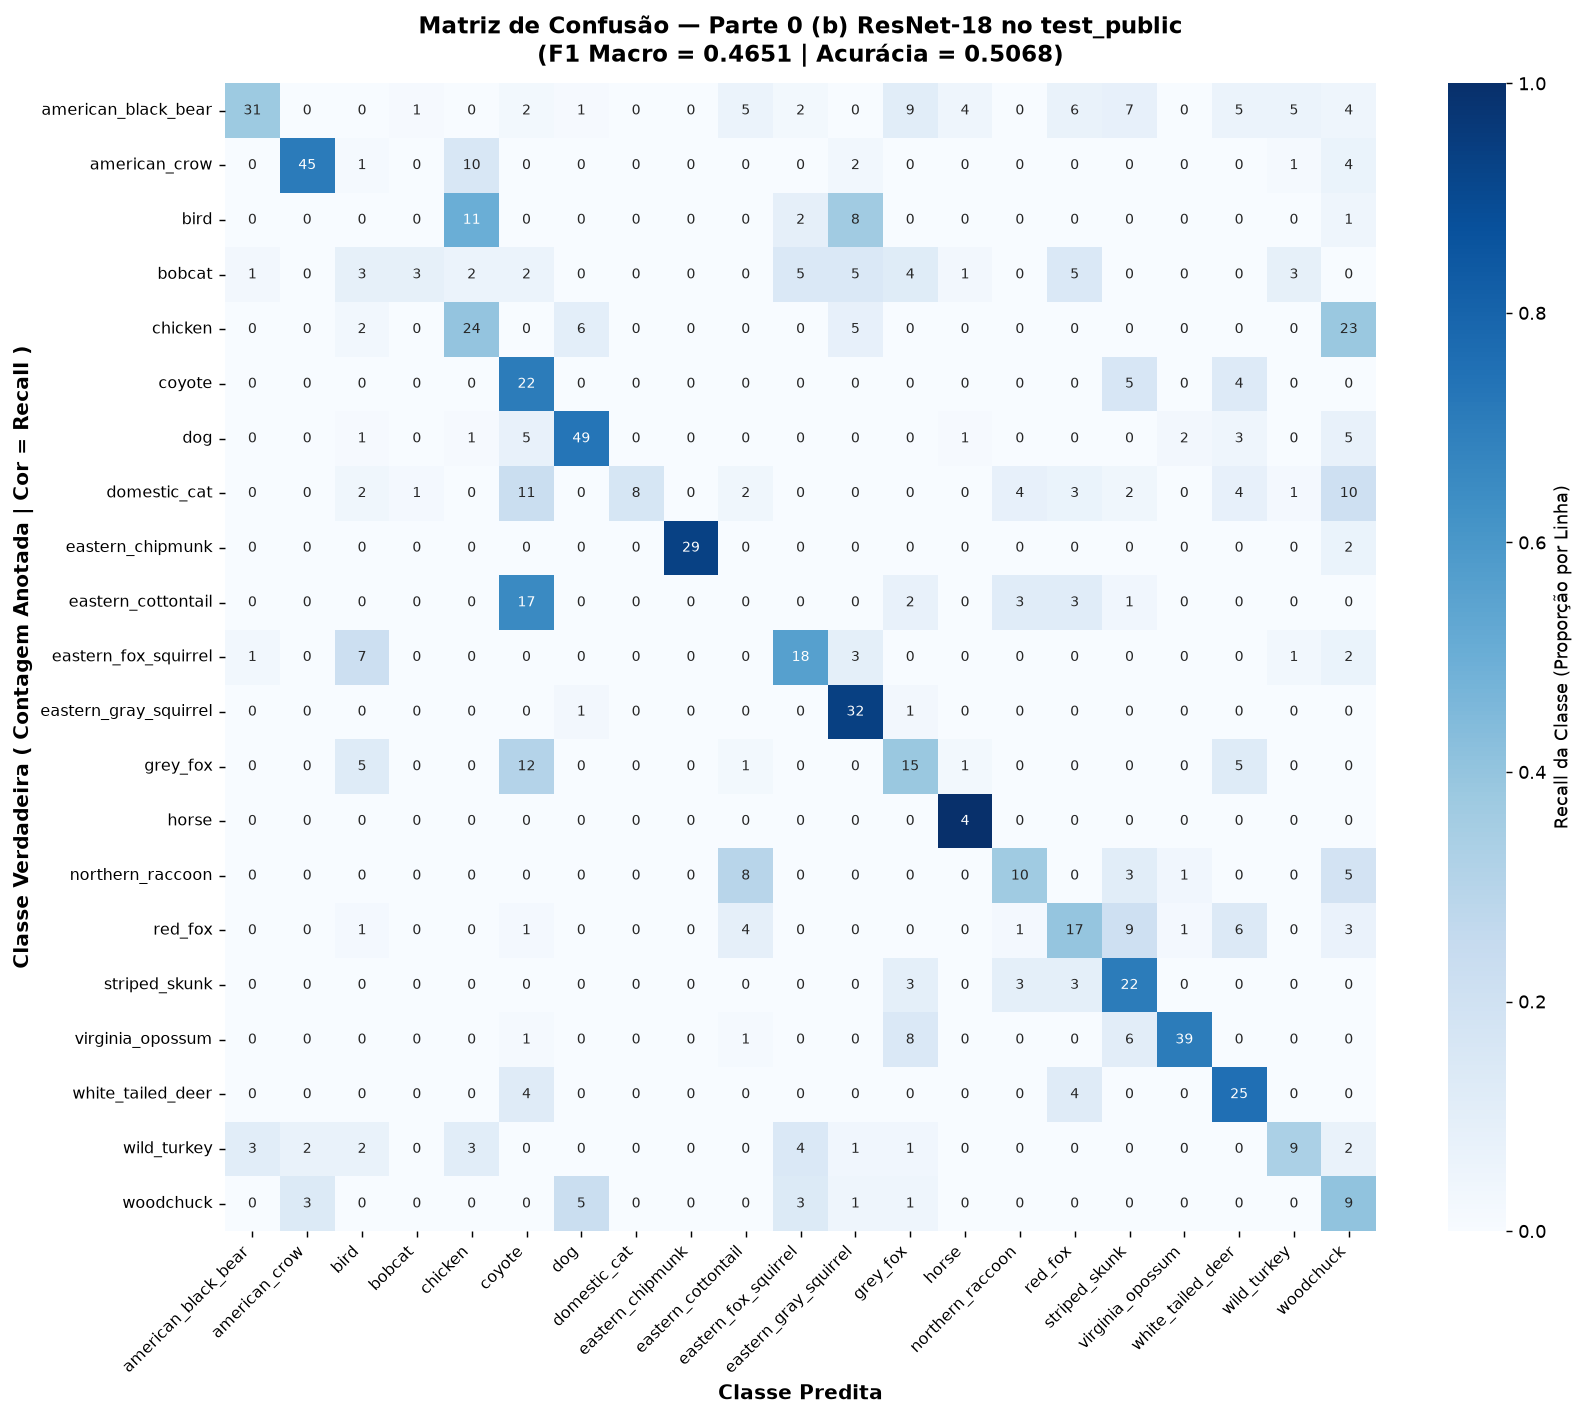

,idx,label,test_support,f1_part0a_small_cnn,f1_part0b_resnet18,gain_b_minus_a
0,8,eastern_chipmunk,31,0.666667,0.966667,0.300000
1,1,american_crow,63,0.146341,0.796460,0.650119
2,17,virginia_opossum,55,0.309278,0.795918,0.486640
3,6,dog,67,0.172043,0.759690,0.587647
4,11,eastern_gray_squirrel,34,0.000000,0.703297,0.703297
5,18,white_tailed_deer,33,0.376812,0.588235,0.211424
6,10,eastern_fox_squirrel,32,0.265060,0.545455,0.280394
7,13,horse,4,0.000000,0.533333,0.533333
8,0,american_black_bear,82,0.000000,0.525424,0.525424
9,16,striped_skunk,31,0.000000,0.511628,0.511628


In [8]:
plot_confusion_matrix(
    cm=test_metrics_b["confusion_matrix"],
    class_names=class_names,
    title=(
        f"Matriz de Confusão — Parte 0 (b) ResNet-18 no test_public\n"
        f"(F1 Macro = {test_metrics_b['f1_macro']:.4f} | Acurácia = {test_metrics_b['accuracy']:.4f})"
    ),
    normalize=True,
    save_path="docs/figures/part0_confusion_matrix_resnet18.png",
    show=True,
)

df_per_class_p0 = build_per_class_f1_table(
    class_names=class_names,
    df_test=df_test,
    test_metrics_a=test_metrics_a,
    test_metrics_b=test_metrics_b,
    save_path="results/part0_per_class_f1.csv",
)
display(df_per_class_p0.sort_values("f1_part0b_resnet18", ascending=False).reset_index(drop=True))

## 5. Parte 1 — Usando o que Não Tem Rótulo (Trilha C: Professor e Aluno)

Exploração das **6.505 imagens não rotuladas** do `train` utilizando a **Trilha C (Professor e Aluno)**:
- Um *foundation model* aberto atua como **Professor**, avaliando seu F1 *zero-shot* no `test_public` e gerando pseudo-rótulos sobre o `train`.
- Análise da matriz de confusão do professor (ruído sistemático em fotos noturnas, animais pequenos e classes similares como `bird` e `american_crow`).
- Tratamento do ruído dos pseudo-rótulos (filtragem por confiança / temperatura / combinação com os 105 rótulos humanos de `rotulos_5.csv`) para treinar o modelo **Aluno (`ResNet-18`, <= 12M parâmetros)**.

In [ ]:
# [Planejado] Implementação da Trilha C (Professor e Aluno) na Parte 1

## 6. Parte 2 — A Curva de Orçamento

- Orçamentos avaliados: **1, 5 e 20 rótulos por classe**.
- No orçamento de 5 rótulos: **3 seeds** para cálculo de média $\pm$ desvio padrão.
- Gráfico semi-log: F1 Macro no `test_public` vs. número de rótulos (Piso vs. Aluno Trilha C vs. Professor vs. Teto `0,686`).
- Exportação para `results/curva_orcamento.csv`.

In [ ]:
# [Planejado] Execução das ablações de orçamento (Parte 2)

## 7. Parte 3 — Galeria de Falhas e Atalhos (Saliência / Grad-CAM)

Inspeção interpretável das decisões do modelo final:
- **3 Falhas:** Imagem, classe verdadeira, classe predita, confiança e mapa de calor do Grad-CAM.
- **5 Acertos:** Análise se a predição foi motivada pelo animal ou por atalhos espúrios do fundo.

In [ ]:
# [Planejado] Grad-CAM e visualização de saliência (Parte 3)

## 8. Exportação do Modelo e Teste de Inferência CPU (`predict.py`)

In [ ]:
# [Planejado] Salvamento dos pesos finais em checkpoints/best_model.pt
# e verificação da inferência isolada em CPU via predict.py